# XGBoost Student Pass/Fail Prediction (Classification)

Standalone notebook for XGBoost (+ optional Optuna). Uses the same weekly snapshot + group-aware split as the baseline notebook.


## 1. Setup

In [1]:

import numpy as np
import pandas as pd
import os
from pathlib import Path

import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, recall_score, precision_recall_curve, precision_score, fbeta_score

# XGBoost / Optuna
try:
    from xgboost import XGBClassifier
    from xgboost.callback import EarlyStopping
except Exception as e:
    raise ImportError("xgboost is required. Install with: pip install xgboost") from e

try:
    import optuna
    from optuna.pruners import MedianPruner
    OPTUNA_AVAILABLE = True
except Exception as e:
    print(f"Warning: Optuna not available ({e}). Install with: pip install optuna")
    OPTUNA_AVAILABLE = False

# -----------------------
# Paths (repo-style)
# -----------------------
REPO_ROOT = Path.cwd()
if REPO_ROOT.name.lower() in {"notebooks", "notebook"}:
    REPO_ROOT = REPO_ROOT.parent

PROC_DIR = REPO_ROOT / "data" / "processed"

DEFAULT_REPORTS_ROOT = REPO_ROOT / "reports"
REPORTS_ROOT = Path(os.environ.get("EWS_REPORTS_DIR", str(DEFAULT_REPORTS_ROOT)))

OUT_ROOT = REPORTS_ROOT / "xgb_classification"
FIG_DIR  = OUT_ROOT / "figures"
TAB_DIR  = OUT_ROOT / "tables"
FEAT_DIR = OUT_ROOT / "features"

for d in [OUT_ROOT, FIG_DIR, TAB_DIR, FEAT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def slug(s: str) -> str:
    return (
        str(s).strip()
        .replace(" ", "_")
        .replace("|", "_")
        .replace("/", "_")
        .replace("\\", "_")
        .replace("__", "_")
    )

def savefig(path: Path, dpi: int = 200):
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    print("Saved figure:", path)
    return path

print("Repo root:", REPO_ROOT)
print("Processed:", PROC_DIR)
print("Reports:", OUT_ROOT)


Repo root: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project
Processed: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/data/processed
Reports: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification


/Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load data

In [2]:

df = pd.read_csv(PROC_DIR / "ews_feature_store.csv")

print("Shape:", df.shape)
print("Week range:", int(df["week"].min()), "->", int(df["week"].max()))
print("Students:", f'{df["student_id"].nunique():,}')
df.head()


Shape: (579438, 99)
Week range: 0 -> 38
Students: 25,516


,student_id,code_module,code_presentation,week,cum_weekly_clicks_dataplus,cum_weekly_clicks_dualpane,cum_weekly_clicks_externalquiz,cum_weekly_clicks_folder,cum_weekly_clicks_forumng,cum_weekly_clicks_glossary,...,target_score_norm,weight_covered,weighted_score_week,weight_covered_week,cumulative_weighted_score_assess,weight_covered_assess,total_weight_assess,remaining_weight_assess,max_possible_final_score_assess,mathematically_impossible_to_pass
0,6516,AAA,2014J,0,0,0,0,0,124,0,...,63.5,100.0,0.0,0.0,0.0,0.0,200.0,200.0,200.0,0
1,6516,AAA,2014J,1,0,0,0,0,146,0,...,63.5,100.0,0.0,0.0,0.0,0.0,200.0,200.0,200.0,0
2,6516,AAA,2014J,2,0,0,0,0,158,0,...,63.5,100.0,6.0,10.0,6.0,10.0,200.0,190.0,196.0,0
3,6516,AAA,2014J,3,0,0,0,0,164,0,...,63.5,100.0,0.0,0.0,6.0,10.0,200.0,190.0,196.0,0
4,6516,AAA,2014J,4,7,0,0,0,184,0,...,63.5,100.0,0.0,0.0,6.0,10.0,200.0,190.0,196.0,0


## 3. Config + helpers

In [3]:
KEYS = ["student_id", "code_module", "code_presentation"]
TARGET_COL = "target_pass"
IDENTIFIER_COLS = ["student_id", "code_module", "code_presentation", "week"]

# Drop-from-X always (outcomes + structural/oracle assessment features)
LEAKAGE_COLS = [
    "date_unregistration",
    "final_result",
    "target_score",
    "target_score_norm",
    "weight_covered",
    "weight_covered_assess",
    "total_weight_assess",
    "remaining_weight_assess",
    "max_possible_final_score_assess",
    "mathematically_impossible_to_pass",
    "gender",
    "region",
    "imd_band",
    "age_band",
    "disability",
]

# Safe assessment progress features (optional to include)
ASSESSMENT_SAFE_COLS = [
    "weighted_score_week",
    "weight_covered_week",
    "cumulative_weighted_score_assess",
]

DEMOGRAPHIC_COLS = [
    "highest_education",
    "num_of_prev_attempts",
    "studied_credits",
    "module_presentation_length",
]

PERSONAL_INFO_COLS = ["gender", "region", "imd_band", "age_band", "disability"]


# Set these variables to enable/configure Optuna tuning
RUN_OPTUNA = True  # Set to True to run hyperparameter optimization
OPTUNA_WEEK = 10    # Week to use for optimization (should be mid-course)
OPTUNA_N_TRIALS = 20   # Number of trials
OPTUNA_N_SPLITS = 2    # CV splits

# Feature regime for optimization (same as main experiment)
OPTUNA_DROP_COLS = []  # Full realistic features

## 4. Hyperparameter Tuning with Optuna (Optional)

Optimize XGBoost hyperparameters using Optuna on a representative week. This can significantly improve model performance.

The optimization uses Median Pruning to stop unpromising trials early, saving computation time. This should give you a meaningful boost in accuracy compared to the default parameters.


In [4]:
# ============================================================================
# OPTIONAL: Run Optuna hyperparameter tuning
# ============================================================================

def build_xy_for_week_snapshot(df: pd.DataFrame, t: int, *, drop_cols=None, target_col: str = TARGET_COL):
    d = df[df["week"] <= t].copy()
    d = d.sort_values(KEYS + ["week"])
    d = d.groupby(KEYS, as_index=False).tail(1)

    d = d[d[target_col].notna()].copy()
    d[target_col] = d[target_col].astype(int)

    groups = d["student_id"].copy()

    drops = set(LEAKAGE_COLS + IDENTIFIER_COLS)
    if drop_cols:
        drops |= set(drop_cols)
    drops.discard(target_col)

    d = d.drop(columns=[c for c in drops if c in d.columns], errors="ignore")

    y = d[target_col].copy()
    X = d.drop(columns=[target_col])
    return X, y, groups

def to_fail_positive(y_orig: pd.Series) -> pd.Series:
    # original: fail=0, pass=1  -> fail-positive: fail=1, pass=0
    return (y_orig == 0).astype(int)

def make_xgb(y_train_failpos: pd.Series, seed: int = 42, params: dict | None = None) -> XGBClassifier:
    pos = int((y_train_failpos == 1).sum())
    neg = int((y_train_failpos == 0).sum())
    scale_pos_weight = neg / max(pos, 1)

    base = dict(
        objective="binary:logistic",
        eval_metric="auc",
        random_state=seed,
        n_jobs=-1,
        tree_method="hist",
        scale_pos_weight=scale_pos_weight,
    )
    if params:
        base.update(params)
    return XGBClassifier(**base)

def optimize_hyperparams(df, t: int, *, drop_cols, n_trials=50, n_splits=3, seed=42):
    """Run Optuna optimization on a specific week snapshot."""
    
    if not OPTUNA_AVAILABLE:
        print("Optuna not available. Using default parameters.")
        return None
    
    print(f"\n{'='*60}")
    print(f"Starting Optuna Hyperparameter Tuning for Week {t}")
    print(f"{'='*60}")
    print(f"n_trials: {n_trials}, n_splits: {n_splits}")
    print()
    
    # Build data for week t
    X, y_orig, groups = build_xy_for_week_snapshot(df, t, drop_cols=drop_cols)
    y = to_fail_positive(y_orig)
    
    print(f"Data shape: {X.shape}")
    print(f"Fail ratio: {(y == 1).sum() / len(y):.3f}")
    print()
    
    # Create study with median pruning
    study = optuna.create_study(
        direction='maximize',
        pruner=MedianPruner(n_startup_trials=5, n_warmup_steps=0)
    )
    
    # Optimize
    study.optimize(
        lambda trial: optuna_objective(trial, X, y, groups, drop_cols, seed=seed, n_splits=n_splits),
        n_trials=n_trials,
        show_progress_bar=True
    )
    
    # Print results
    print(f"\n{'='*60}")
    print(f"Optimization Results")
    print(f"{'='*60}")
    print(f"Best Trial: {study.best_trial.number}")
    print(f"Best AUC: {study.best_value:.4f}\n")
    
    print("Best Parameters:")
    for key, value in study.best_params.items():
        print(f"  {key}: {value}")
    print()
    
    return study

def optuna_objective(trial, X_train, y_train, groups_train, drop_cols, seed=42, n_splits=3):
    """Optuna objective with StratifiedGroupKFold + fold-level pruning (no early stopping)."""

    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 350),   # tighter for speed
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'min_child_weight': trial.suggest_float('min_child_weight', 1.0, 8.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 5.0),
    }

    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    aucs = []

    for fold_i, (train_idx, val_idx) in enumerate(sgkf.split(X_train, y_train, groups_train), start=1):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        prep = make_preprocessor(X_tr)
        X_tr_p = prep.fit_transform(X_tr)
        X_val_p = prep.transform(X_val)

        clf = make_xgb(y_tr, seed=seed, params=params)
        clf.fit(X_tr_p, y_tr, verbose=0)

        y_pred_proba = clf.predict_proba(X_val_p)[:, 1]
        auc = roc_auc_score(y_val, y_pred_proba)
        aucs.append(float(auc))

        # report partial progress so Optuna can prune after fold 1
        trial.report(float(np.mean(aucs)), step=fold_i)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(aucs))


def make_preprocessor(X: pd.DataFrame) -> ColumnTransformer:
    num_cols = X.select_dtypes(include=["int64", "int32", "float64", "float32"]).columns.tolist()
    cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

    num_pipe = Pipeline(steps=[
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])

    cat_pipe = Pipeline(steps=[
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    return ColumnTransformer(
        transformers=[
            ("num", num_pipe, num_cols),
            ("cat", cat_pipe, cat_cols),
        ],
        remainder="drop",
    )

if RUN_OPTUNA and OPTUNA_AVAILABLE:
    # Load data for optimization
    optuna_df = pd.read_csv(PROC_DIR / "ews_feature_store.csv")
    
    # Run optimization
    study = optimize_hyperparams(
        optuna_df,
        t=OPTUNA_WEEK,
        drop_cols=OPTUNA_DROP_COLS,
        n_trials=OPTUNA_N_TRIALS,
        n_splits=OPTUNA_N_SPLITS,
        seed=42
    )
    
    # Extract best params
    best_params = study.best_params
    print("\n✓ Optuna optimization complete!")
    print("Copy the best_params dict below to use in the next section:")
    print(f"\nbest_params = {best_params}\n")
else:
    print("Optuna tuning skipped. Set RUN_OPTUNA=True to enable.")
    best_params = None


def back_to_orig_label(y_failpos: np.ndarray) -> np.ndarray:
    return (1 - y_failpos).astype(int)

def get_feature_names_clean(prep: ColumnTransformer) -> np.ndarray:
    names = prep.get_feature_names_out()
    names = np.array([n.replace("num__", "").replace("cat__", "") for n in names])
    nice = []
    for n in names:
        if "_" in n:
            col, level = n.split("_", 1)
            nice.append(f"{col}={level}")
        else:
            nice.append(n)
    return np.array(nice)

def split_group(X, y, groups, test_size=0.2, seed=42):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    tr_idx, te_idx = next(gss.split(X, y, groups))
    return tr_idx, te_idx

def run_xgb_week(df, t: int, *, drop_cols, params=None, threshold=0.5, seed=42, test_size=0.2):
    X, y_orig, groups = build_xy_for_week_snapshot(df, t, drop_cols=drop_cols)
    y = to_fail_positive(y_orig)

    tr_idx, te_idx = split_group(X, y, groups, test_size=test_size, seed=seed)
    X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
    y_tr, y_te = y.iloc[tr_idx], y.iloc[te_idx]

    prep = make_preprocessor(X_tr)
    X_tr_p = prep.fit_transform(X_tr)
    X_te_p = prep.transform(X_te)

    clf = make_xgb(y_tr, seed=seed, params=params)
    clf.fit(X_tr_p, y_tr)

    p_fail = clf.predict_proba(X_te_p)[:, 1]
    pred_fail = (p_fail >= threshold).astype(int)

    auc_fail = float(roc_auc_score(y_te, p_fail))

    # confusion in original space
    y_te_orig = back_to_orig_label(y_te.to_numpy())
    y_pred_orig = back_to_orig_label(pred_fail)
    cm = confusion_matrix(y_te_orig, y_pred_orig, labels=[0, 1])

    return dict(
        week_t=int(t),
        auc_fail=auc_fail,
        n_test=int(len(y_te)),
        cm=cm,
        clf=clf,
        prep=prep,
        feature_names=get_feature_names_clean(prep),
        p_fail=p_fail,
        pred_fail=pred_fail,
    )


Starting Optuna Hyperparameter Tuning for Week 10
n_trials: 20, n_splits: 2



[I 2026-01-30 12:26:41,134] A new study created in memory with name: no-name-b8408ef7-07b5-442c-8d70-dc0c5906d4ae


Data shape: (28393, 79)
Fail ratio: 0.460



  0%|          | 0/20 [00:00<?, ?it/s]/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or

[I 2026-01-30 12:26:43,070] Trial 0 finished with value: 0.8552458065823982 and parameters: {'n_estimators': 297, 'max_depth': 3, 'learning_rate': 0.058142952700645505, 'subsample': 0.8561160016667477, 'colsample_bytree': 0.9207605191961236, 'min_child_weight': 2.6531707210446354, 'reg_lambda': 4.053205674174545}. Best is trial 0 with value: 0.8552458065823982.


/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silen

... (33 outputs left out)

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
Best trial: 17. Best value: 0.857769:  95%|█████████▌| 19/20 [00:38<00:02,  2.24s/it]

[I 2026-01-30 12:27:19,412] Trial 18 pruned. 


/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
Best trial: 17. Best value: 0.857769: 100%|██████████| 20/20 [00:39<00:00,  1.98s/it]

[I 2026-01-30 12:27:20,703] Trial 19 pruned. 

Optimization Results
Best Trial: 17
Best AUC: 0.8578

Best Parameters:
  n_estimators: 327
  max_depth: 8
  learning_rate: 0.020031344544966485
  subsample: 0.7044902907395804
  colsample_bytree: 0.8799114289027254
  min_child_weight: 7.954952572962833
  reg_lambda: 4.518998128444178


✓ Optuna optimization complete!
Copy the best_params dict below to use in the next section:

best_params = {'n_estimators': 327, 'max_depth': 8, 'learning_rate': 0.020031344544966485, 'subsample': 0.7044902907395804, 'colsample_bytree': 0.8799114289027254, 'min_child_weight': 7.954952572962833, 'reg_lambda': 4.518998128444178}



## 5. Choose experiment + run over time

In [5]:

# Choose which feature regime you want for XGB
# (1) behaviour-only
DROP_BEHAV_ONLY = ASSESSMENT_SAFE_COLS + DEMOGRAPHIC_COLS + PERSONAL_INFO_COLS

# (2) behaviour + demographics + personal info (no assessment)
DROP_BEHAV_DEMO = ASSESSMENT_SAFE_COLS

# (3) behaviour + safe assessment + demographics + personal info (realistic full)
DROP_FULL_REALISTIC = []

exp_name = "XGB_full_realistic"
drop_cols = DROP_FULL_REALISTIC

weeks = sorted([int(w) for w in df["week"].dropna().unique() if int(w) >= 0])
weeks = [w for w in weeks if w <= 28]

# Use Optuna params if available, otherwise use defaults
if best_params is not None:
    # If you want to modify Optuna params, do it here
    xgb_params = best_params.copy()
    print(f"Using Optuna-optimized parameters from week {OPTUNA_WEEK}")
else:
    # Default parameters
    xgb_params = dict(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        min_child_weight=5.0,
        reg_lambda=1.0,
    )
    print("Using default parameters")

print("XGBoost Parameters:")
for key, value in xgb_params.items():
    print(f"  {key}: {value}")
print()

threshold = 0.5

rows = []
cms = []

for t in weeks:
    r = run_xgb_week(df, t, drop_cols=drop_cols, params=xgb_params, threshold=threshold)
    rows.append({"week_t": r["week_t"], "roc_auc_fail": r["auc_fail"], "n_test": r["n_test"]})
    cms.append(r["cm"])
    print(f"Week {t:>2}: AUC_fail={r['auc_fail']:.3f} | n={r['n_test']}")

auc_df = pd.DataFrame(rows).sort_values("week_t").reset_index(drop=True)
auc_path = TAB_DIR / f"xgb_auc_over_time__{slug(exp_name)}__thr{threshold:.2f}.csv"
auc_df.to_csv(auc_path, index=False)
print("Saved:", auc_path)

auc_df.head()


Using Optuna-optimized parameters from week 10
XGBoost Parameters:
  n_estimators: 327
  max_depth: 8
  learning_rate: 0.020031344544966485
  subsample: 0.7044902907395804
  colsample_bytree: 0.8799114289027254
  min_child_weight: 7.954952572962833
  reg_lambda: 4.518998128444178



/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Week  0: AUC_fail=0.694 | n=4723


/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Week  1: AUC_fail=0.710 | n=5287


/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


... (50 outputs left out)

Week 27: AUC_fail=0.961 | n=5718


/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Week 28: AUC_fail=0.964 | n=5716
Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/tables/xgb_auc_over_time__XGB_full_realistic__thr0.50.csv


,week_t,roc_auc_fail,n_test
0,0,0.693793,4723
1,1,0.710172,5287
2,2,0.766672,5510
3,3,0.779262,5571
4,4,0.804870,5617


## 6. Optimize threshold (minimize false negatives)


/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silen


THRESHOLD OPTIMIZATION RESULTS

OPTION 1: F2-OPTIMIZED (Emphasize catching failures)
  Threshold: 0.190
  F2-score:  0.8558
  Recall:    0.9521 (95.2% of failing students caught)
  Precision: 0.6092 (60.9% of flagged are actually failing)
  → 2194 false alarms per ~5,600 test samples

OPTION 2: F1-OPTIMIZED (Balanced precision-recall)
  Threshold: 0.450
  F1-score:  0.7949
  Recall:    0.8045 (80.4% of failing students caught)
  Precision: 0.7855 (78.5% of flagged are actually failing)
  → 1204 false alarms per ~5,600 test samples


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_threshold_optimization_comparison__XGB_full_realistic.png


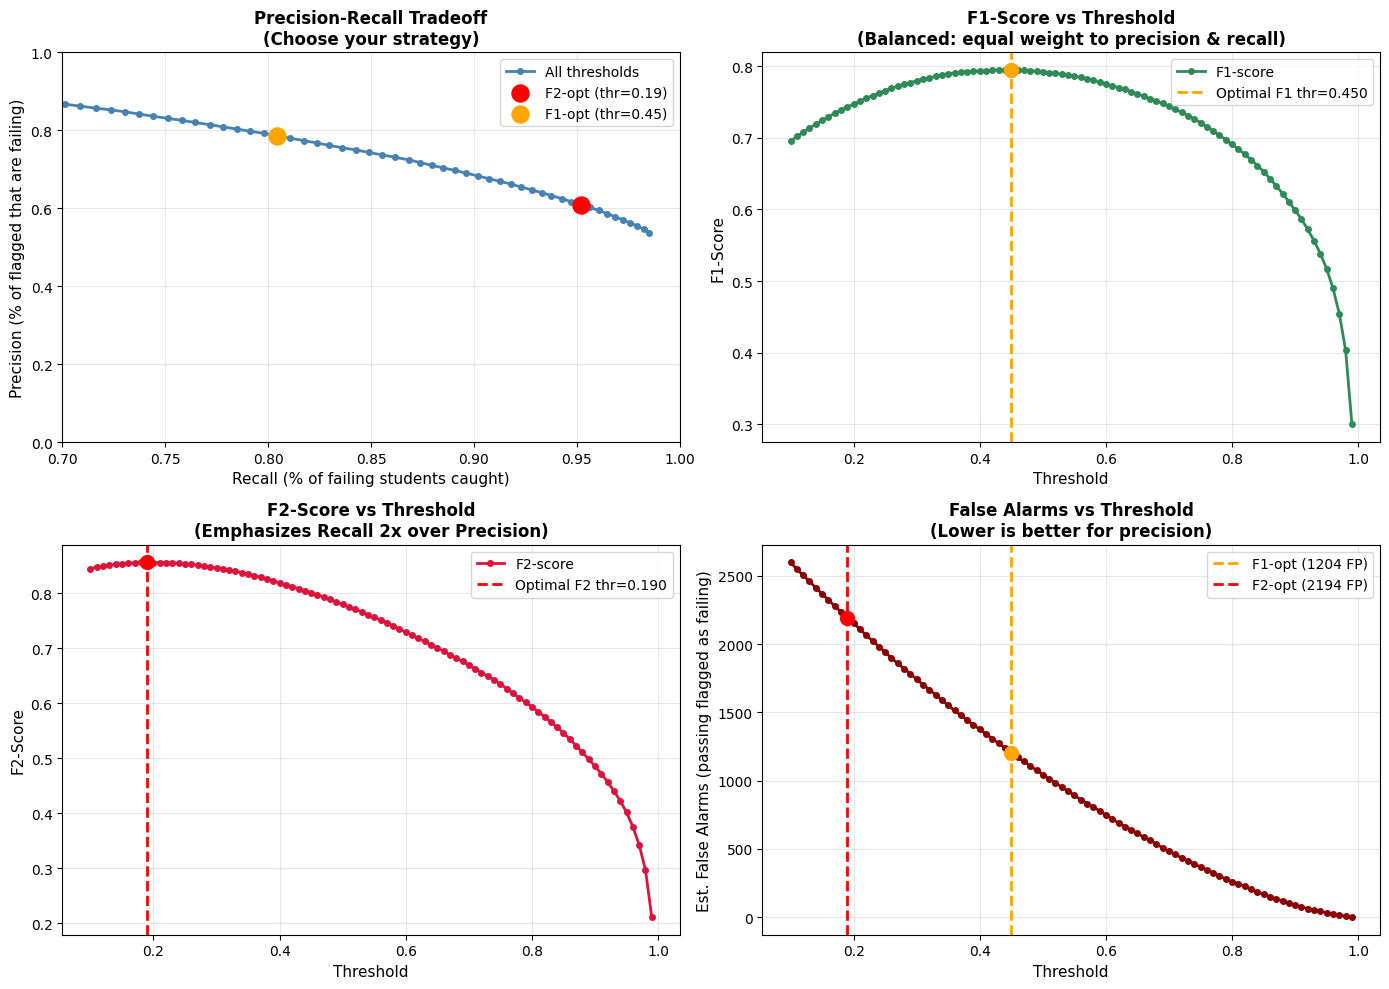

Top 5 Thresholds by F1-Score (BALANCED):
 threshold  f1_score  f2_score   recall  precision
      0.45  0.794873  0.800607 0.804476   0.785496
      0.46  0.794818  0.796647 0.797871   0.791788
      0.44  0.794804  0.804311 0.810776   0.779449
      0.43  0.794663  0.808062 0.817249   0.773291
      0.42  0.794439  0.811730 0.823682   0.767201

Top 5 Thresholds by F2-Score (RECALL-FOCUSED):
 threshold  f2_score  f1_score   recall  precision
      0.19  0.855771  0.743022 0.952086   0.609241
      0.18  0.855605  0.738781 0.956432   0.601827
      0.21  0.855490  0.751227 0.942716   0.624397
      0.20  0.855436  0.746841 0.947261   0.616419
      0.17  0.855103  0.734225 0.960526   0.594225

RECOMMENDATION:
If you want BALANCED performance (fewer false alarms):
  → Use F1-optimized threshold: 0.450
     Catches 80.4% of failures, 1204 false alarms

If you want SAFETY-FIRST (catch almost all failures):
  → Use F2-optimized threshold: 0.190
     Catches 95.2% of failures, 2194 false ala

In [6]:
from sklearn.metrics import f1_score, fbeta_score, precision_score

# Find optimal threshold using data from all weeks
# Collect all predictions across all weeks
all_y_true = []
all_y_pred_proba = []

print("Collecting predictions across all weeks for threshold optimization...")
for t in weeks:
    r = run_xgb_week(df, t, drop_cols=drop_cols, params=xgb_params, threshold=0.5)
    y_te_orig = back_to_orig_label(r['p_fail'] >= 0.5)  # Just for alignment, will use actual proba
    all_y_pred_proba.extend(r['p_fail'])
    # Get actual test labels from the data
    X, y_orig, groups = build_xy_for_week_snapshot(df, t, drop_cols=drop_cols)
    y = to_fail_positive(y_orig)
    tr_idx, te_idx = split_group(X, y, groups, test_size=0.2, seed=42)
    all_y_true.extend(y.iloc[te_idx].values)

all_y_true = np.array(all_y_true)
all_y_pred_proba = np.array(all_y_pred_proba)

# Find optimal threshold based on F2-score (emphasizes recall 2x) AND F1-score (balanced)
thresholds = np.arange(0.1, 1.0, 0.01)
f2_scores = []
f1_scores = []
recalls = []
precisions = []

for thr in thresholds:
    y_pred = (all_y_pred_proba >= thr).astype(int)
    f2 = fbeta_score(all_y_true, y_pred, beta=2, zero_division=0)
    f1 = f1_score(all_y_true, y_pred, zero_division=0)
    recall = recall_score(all_y_true, y_pred, zero_division=0)
    precision = precision_score(all_y_true, y_pred, zero_division=0)
    
    f2_scores.append(f2)
    f1_scores.append(f1)
    recalls.append(recall)
    precisions.append(precision)

# Find best thresholds
f2_best_idx = np.argmax(f2_scores)
f1_best_idx = np.argmax(f1_scores)

f2_optimal_threshold = thresholds[f2_best_idx]
f2_optimal_f2 = f2_scores[f2_best_idx]
f2_optimal_recall = recalls[f2_best_idx]
f2_optimal_precision = precisions[f2_best_idx]

f1_optimal_threshold = thresholds[f1_best_idx]
f1_optimal_f1 = f1_scores[f1_best_idx]
f1_optimal_recall = recalls[f1_best_idx]
f1_optimal_precision = precisions[f1_best_idx]

print(f"\n{'='*70}")
print(f"THRESHOLD OPTIMIZATION RESULTS")
print(f"{'='*70}\n")

print(f"OPTION 1: F2-OPTIMIZED (Emphasize catching failures)")
print(f"  Threshold: {f2_optimal_threshold:.3f}")
print(f"  F2-score:  {f2_optimal_f2:.4f}")
print(f"  Recall:    {f2_optimal_recall:.4f} ({f2_optimal_recall*100:.1f}% of failing students caught)")
print(f"  Precision: {f2_optimal_precision:.4f} ({f2_optimal_precision*100:.1f}% of flagged are actually failing)")
print(f"  → {int((1-f2_optimal_precision)*5617)} false alarms per ~5,600 test samples\n")

print(f"OPTION 2: F1-OPTIMIZED (Balanced precision-recall)")
print(f"  Threshold: {f1_optimal_threshold:.3f}")
print(f"  F1-score:  {f1_optimal_f1:.4f}")
print(f"  Recall:    {f1_optimal_recall:.4f} ({f1_optimal_recall*100:.1f}% of failing students caught)")
print(f"  Precision: {f1_optimal_precision:.4f} ({f1_optimal_precision*100:.1f}% of flagged are actually failing)")
print(f"  → {int((1-f1_optimal_precision)*5617)} false alarms per ~5,600 test samples\n")

print(f"{'='*70}\n")

# Visualization: Compare both strategies
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Precision-Recall curve with both optima marked
ax1.plot(recalls, precisions, marker="o", linewidth=2, markersize=4, color="steelblue", label="All thresholds")
ax1.scatter([f2_optimal_recall], [f2_optimal_precision], color="red", s=150, zorder=5, label=f"F2-opt (thr={f2_optimal_threshold:.2f})")
ax1.scatter([f1_optimal_recall], [f1_optimal_precision], color="orange", s=150, zorder=5, label=f"F1-opt (thr={f1_optimal_threshold:.2f})")
ax1.set_xlabel("Recall (% of failing students caught)", fontsize=11)
ax1.set_ylabel("Precision (% of flagged that are failing)", fontsize=11)
ax1.set_title("Precision-Recall Tradeoff\n(Choose your strategy)", fontsize=12, fontweight="bold")
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=10)
ax1.set_xlim(0.7, 1)
ax1.set_ylim(0, 1)

# Plot 2: F1-score vs threshold
ax2.plot(thresholds, f1_scores, marker="o", linewidth=2, markersize=4, color="seagreen", label="F1-score")
ax2.axvline(f1_optimal_threshold, color="orange", linestyle="--", linewidth=2, label=f"Optimal F1 thr={f1_optimal_threshold:.3f}")
ax2.scatter([f1_optimal_threshold], [f1_optimal_f1], color="orange", s=100, zorder=5)
ax2.set_xlabel("Threshold", fontsize=11)
ax2.set_ylabel("F1-Score", fontsize=11)
ax2.set_title("F1-Score vs Threshold\n(Balanced: equal weight to precision & recall)", fontsize=12, fontweight="bold")
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=10)

# Plot 3: F2-score vs threshold
ax3.plot(thresholds, f2_scores, marker="o", linewidth=2, markersize=4, color="crimson", label="F2-score")
ax3.axvline(f2_optimal_threshold, color="red", linestyle="--", linewidth=2, label=f"Optimal F2 thr={f2_optimal_threshold:.3f}")
ax3.scatter([f2_optimal_threshold], [f2_optimal_f2], color="red", s=100, zorder=5)
ax3.set_xlabel("Threshold", fontsize=11)
ax3.set_ylabel("F2-Score", fontsize=11)
ax3.set_title("F2-Score vs Threshold\n(Emphasizes Recall 2x over Precision)", fontsize=12, fontweight="bold")
ax3.grid(True, alpha=0.3)
ax3.legend(fontsize=10)

# Plot 4: False positives vs threshold
false_positives = [(1 - p) * 5617 for p in precisions]  # Approximate based on avg test size
ax4.plot(thresholds, false_positives, marker="o", linewidth=2, markersize=4, color="darkred")
ax4.axvline(f1_optimal_threshold, color="orange", linestyle="--", linewidth=2, label=f"F1-opt ({int((1-f1_optimal_precision)*5617)} FP)")
ax4.axvline(f2_optimal_threshold, color="red", linestyle="--", linewidth=2, label=f"F2-opt ({int((1-f2_optimal_precision)*5617)} FP)")
ax4.scatter([f1_optimal_threshold], [int((1-f1_optimal_precision)*5617)], color="orange", s=100, zorder=5)
ax4.scatter([f2_optimal_threshold], [int((1-f2_optimal_precision)*5617)], color="red", s=100, zorder=5)
ax4.set_xlabel("Threshold", fontsize=11)
ax4.set_ylabel("Est. False Alarms (passing flagged as failing)", fontsize=11)
ax4.set_title("False Alarms vs Threshold\n(Lower is better for precision)", fontsize=12, fontweight="bold")
ax4.grid(True, alpha=0.3)
ax4.legend(fontsize=10)

plt.tight_layout()
savefig(FIG_DIR / f"xgb_threshold_optimization_comparison__{slug(exp_name)}.png")
plt.show()

# Create a detailed comparison table
threshold_comparison = pd.DataFrame({
    "threshold": thresholds,
    "f2_score": f2_scores,
    "f1_score": f1_scores,
    "recall": recalls,
    "precision": precisions,
})

print("Top 5 Thresholds by F1-Score (BALANCED):")
print(threshold_comparison.nlargest(5, "f1_score")[["threshold", "f1_score", "f2_score", "recall", "precision"]].to_string(index=False))
print()

print("Top 5 Thresholds by F2-Score (RECALL-FOCUSED):")
print(threshold_comparison.nlargest(5, "f2_score")[["threshold", "f2_score", "f1_score", "recall", "precision"]].to_string(index=False))
print()

# Set which threshold to use (user can change this)
print(f"{'='*70}")
print("RECOMMENDATION:")
print(f"{'='*70}")
print(f"If you want BALANCED performance (fewer false alarms):")
print(f"  → Use F1-optimized threshold: {f1_optimal_threshold:.3f}")
print(f"     Catches {f1_optimal_recall*100:.1f}% of failures, {int((1-f1_optimal_precision)*5617)} false alarms")
print()
print(f"If you want SAFETY-FIRST (catch almost all failures):")
print(f"  → Use F2-optimized threshold: {f2_optimal_threshold:.3f}")
print(f"     Catches {f2_optimal_recall*100:.1f}% of failures, {int((1-f2_optimal_precision)*5617)} false alarms")
print(f"{'='*70}\n")

# Choose which one to use - change this to switch strategies
optimal_threshold = f1_optimal_threshold  # ← CHANGE THIS if you prefer F2-optimization
print(f"✓ Using {f1_optimal_threshold:.3f} (F1-BALANCED strategy) for re-analysis below")


In [7]:

# Re-run analysis with optimal threshold
print("\n" + "="*60)
print("Re-running analysis with OPTIMAL THRESHOLD")
print("="*60)
print(f"Using threshold: {optimal_threshold:.3f}\n")

threshold = optimal_threshold

rows = []
cms = []

for t in weeks:
    r = run_xgb_week(df, t, drop_cols=drop_cols, params=xgb_params, threshold=threshold)
    rows.append({"week_t": r["week_t"], "roc_auc_fail": r["auc_fail"], "n_test": r["n_test"]})
    cms.append(r["cm"])
    print(f"Week {t:>2}: AUC_fail={r['auc_fail']:.3f} | n={r['n_test']}")

auc_df = pd.DataFrame(rows).sort_values("week_t").reset_index(drop=True)
auc_path = TAB_DIR / f"xgb_auc_over_time__{slug(exp_name)}__thr{threshold:.2f}.csv"
auc_df.to_csv(auc_path, index=False)
print(f"\nSaved with optimal threshold: {auc_path}")

print("\nComparison (baseline threshold 0.5 vs optimal):")
print(f"  Baseline (0.50): Results saved separately")
print(f"  Optimal  ({optimal_threshold:.2f}): Results now in auc_df")



Re-running analysis with OPTIMAL THRESHOLD
Using threshold: 0.450



/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Week  0: AUC_fail=0.694 | n=4723


/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Week  1: AUC_fail=0.710 | n=5287


/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


... (49 outputs left out)

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Week 27: AUC_fail=0.961 | n=5718


/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Week 28: AUC_fail=0.964 | n=5716

Saved with optimal threshold: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/tables/xgb_auc_over_time__XGB_full_realistic__thr0.45.csv

Comparison (baseline threshold 0.5 vs optimal):
  Baseline (0.50): Results saved separately
  Optimal  (0.45): Results now in auc_df


## 7. Plot ROC-AUC over time


Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_auc_over_time__XGB_full_realistic__thr0.45.png


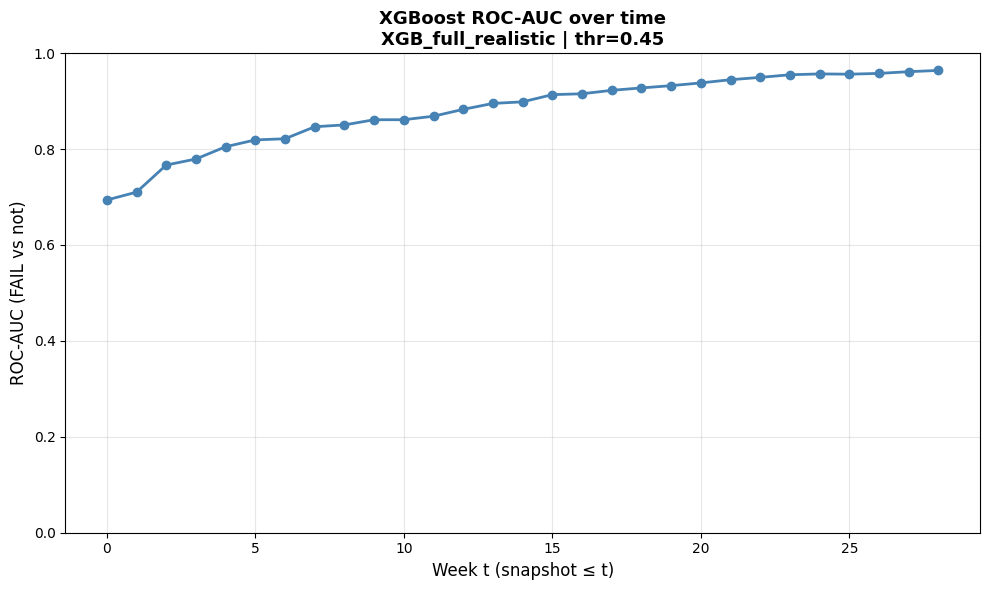


ROC-AUC Summary Statistics:
  Mean AUC: 0.8811
  Std AUC:  0.0759
  Min AUC:  0.6938 (week 0)
  Max AUC:  0.9639 (week 28)


In [8]:

plt.figure(figsize=(10, 6))
plt.plot(auc_df["week_t"], auc_df["roc_auc_fail"], marker="o", linewidth=2, markersize=6, color="steelblue")
plt.xlabel("Week t (snapshot ≤ t)", fontsize=12)
plt.ylabel("ROC-AUC (FAIL vs not)", fontsize=12)
plt.ylim(0.0, 1.0)
plt.title(f"XGBoost ROC-AUC over time\n{exp_name} | thr={threshold:.2f}", fontsize=13, fontweight="bold")
plt.grid(True, alpha=0.3)
plt.tight_layout()
savefig(FIG_DIR / f"xgb_auc_over_time__{slug(exp_name)}__thr{threshold:.2f}.png")
plt.show()

# Print summary statistics
print(f"\nROC-AUC Summary Statistics:")
print(f"  Mean AUC: {auc_df['roc_auc_fail'].mean():.4f}")
print(f"  Std AUC:  {auc_df['roc_auc_fail'].std():.4f}")
print(f"  Min AUC:  {auc_df['roc_auc_fail'].min():.4f} (week {auc_df.loc[auc_df['roc_auc_fail'].idxmin(), 'week_t']:.0f})")
print(f"  Max AUC:  {auc_df['roc_auc_fail'].max():.4f} (week {auc_df.loc[auc_df['roc_auc_fail'].idxmax(), 'week_t']:.0f})")

## 8. Confusion matrices (selected weeks)

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_cm__XGB_full_realistic__week0__thr0.45.png


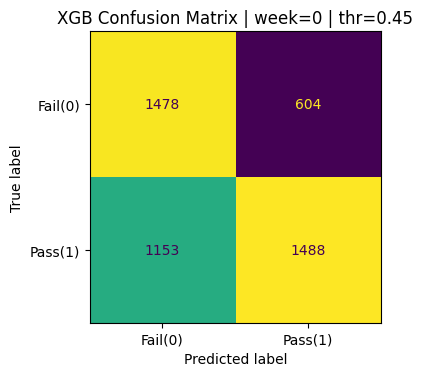

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_cm__XGB_full_realistic__week2__thr0.45.png


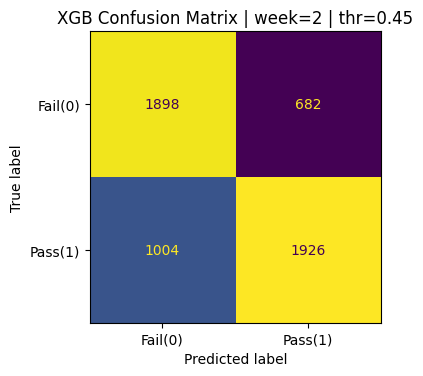

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_cm__XGB_full_realistic__week4__thr0.45.png


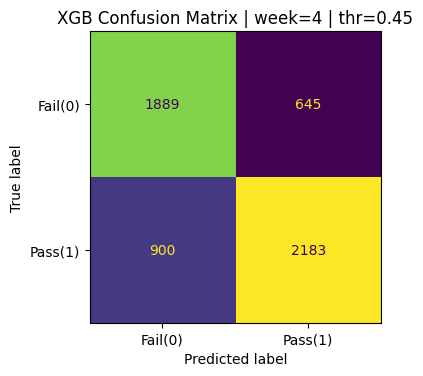

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_cm__XGB_full_realistic__week6__thr0.45.png


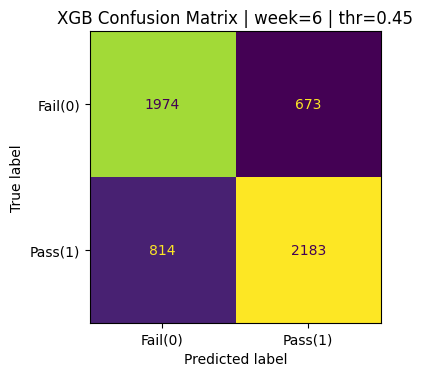

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_cm__XGB_full_realistic__week8__thr0.45.png


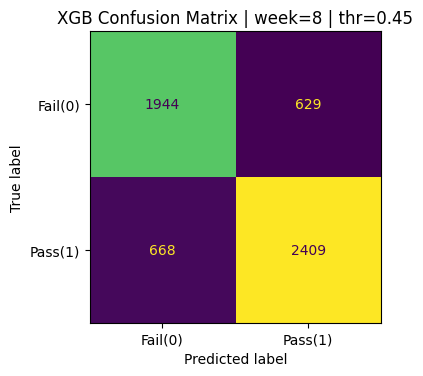

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_cm__XGB_full_realistic__week10__thr0.45.png


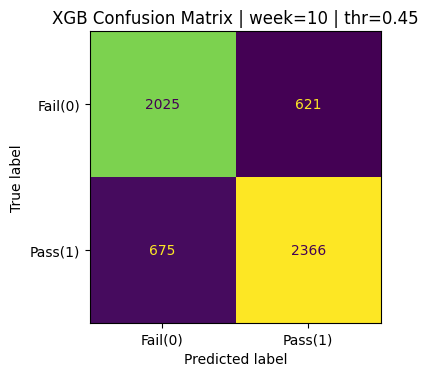

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_cm__XGB_full_realistic__week12__thr0.45.png


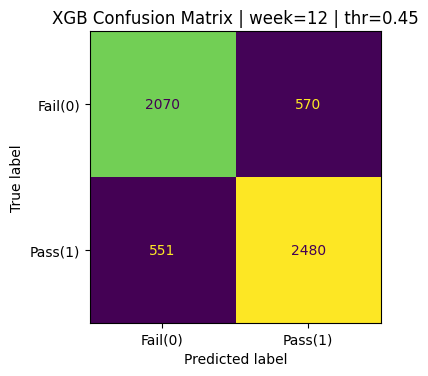

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_cm__XGB_full_realistic__week14__thr0.45.png


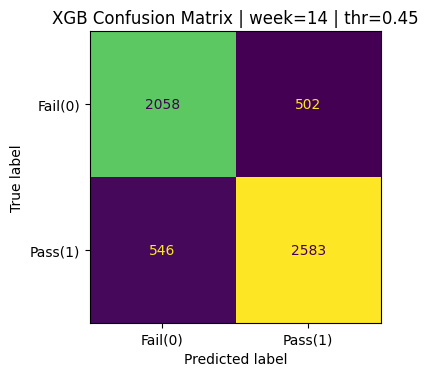

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_cm__XGB_full_realistic__week16__thr0.45.png


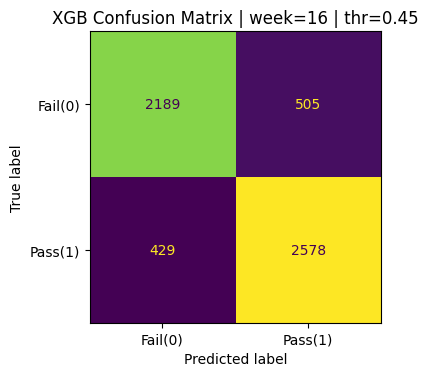

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_cm__XGB_full_realistic__week18__thr0.45.png


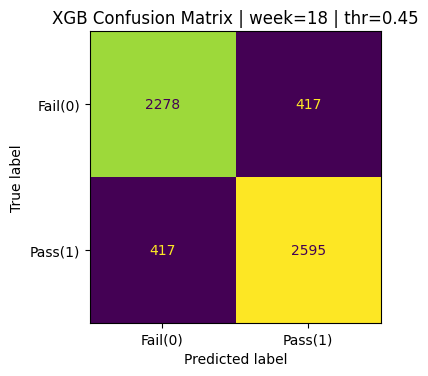

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_cm__XGB_full_realistic__week20__thr0.45.png


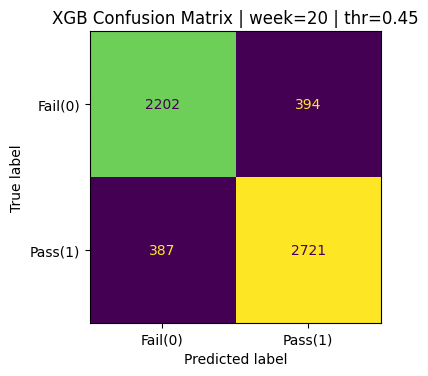

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_cm__XGB_full_realistic__week22__thr0.45.png


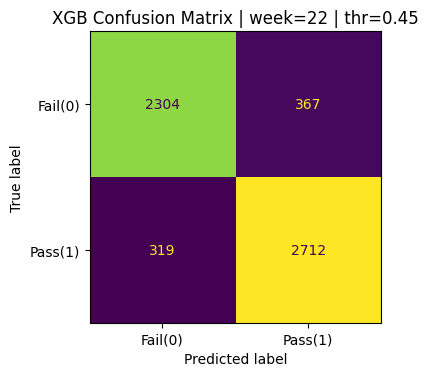

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_cm__XGB_full_realistic__week24__thr0.45.png


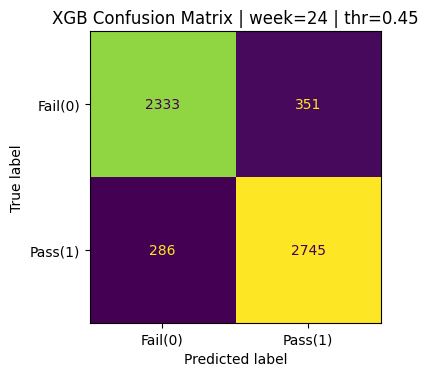

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_cm__XGB_full_realistic__week26__thr0.45.png


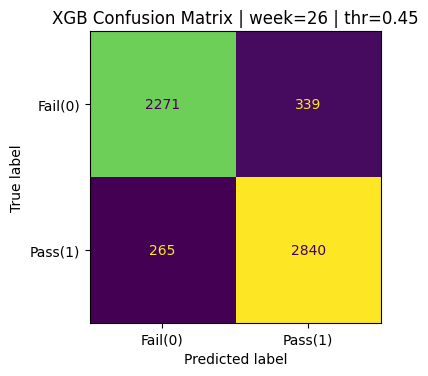

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_cm__XGB_full_realistic__week28__thr0.45.png


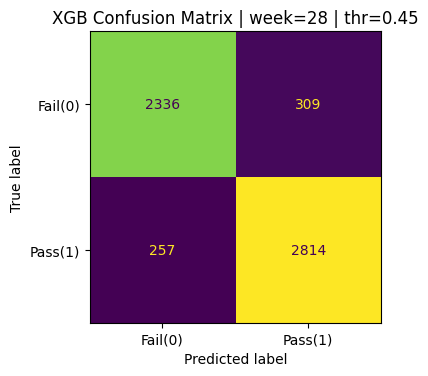

Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/tables/xgb_confusion_matrices__XGB_full_realistic__thr0.45__every2w.csv


,week_t,tn,fp,fn,tp,threshold
0,0,1478,604,1153,1488,0.45
1,2,1898,682,1004,1926,0.45
2,4,1889,645,900,2183,0.45
3,6,1974,673,814,2183,0.45
4,8,1944,629,668,2409,0.45
5,10,2025,621,675,2366,0.45
6,12,2070,570,551,2480,0.45
7,14,2058,502,546,2583,0.45
8,16,2189,505,429,2578,0.45
9,18,2278,417,417,2595,0.45


In [9]:

step = 2
cm_rows = []

for t, cm in zip(auc_df["week_t"].tolist(), cms):
    if t % step != 0:
        continue

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Fail(0)", "Pass(1)"])
    fig, ax = plt.subplots(figsize=(4, 4))
    disp.plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(f"XGB Confusion Matrix | week={t} | thr={threshold:.2f}")
    plt.tight_layout()
    fig_path = FIG_DIR / f"xgb_cm__{slug(exp_name)}__week{t}__thr{threshold:.2f}.png"
    fig.savefig(fig_path, dpi=200, bbox_inches="tight")
    print("Saved figure:", fig_path)
    plt.show()

    tn, fp, fn, tp = cm.ravel()
    cm_rows.append({"week_t": int(t), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp), "threshold": float(threshold)})

cm_df = pd.DataFrame(cm_rows).sort_values("week_t").reset_index(drop=True)
cm_path = TAB_DIR / f"xgb_confusion_matrices__{slug(exp_name)}__thr{threshold:.2f}__every{step}w.csv"
cm_df.to_csv(cm_path, index=False)
print("Saved:", cm_path)

cm_df


## 9. Feature importance (gain) over time

/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
/var/folders/n0/g9ytmk9j4wn9914z0n7xdrl00000gn/T/ipykernel_74300/1918690019.py:136: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silen

Saved: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/features/xgb_top_features_over_time__XGB_full_realistic__every1w__gain.csv
Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_feature_importance_heatmap__XGB_full_realistic__thr0.45.png


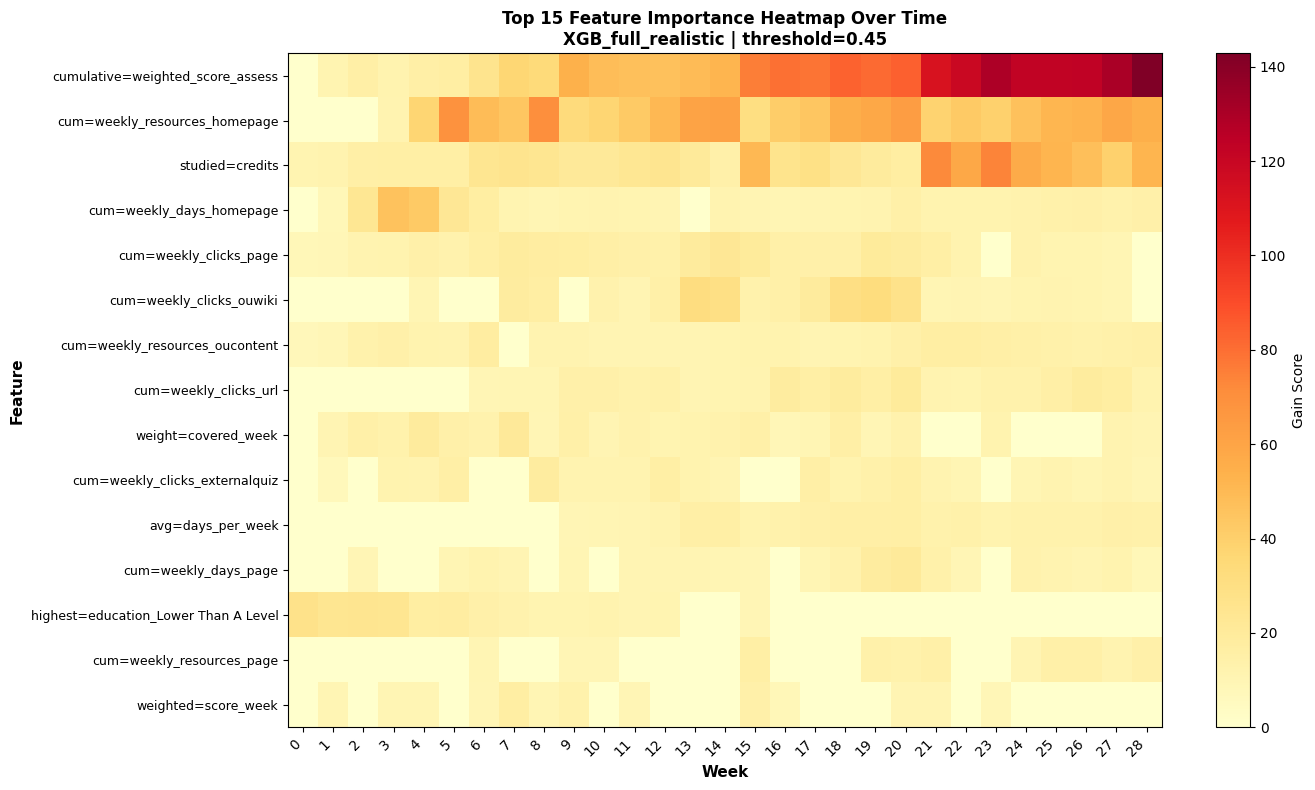

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_feature_importance_top15__week0__thr0.45.png


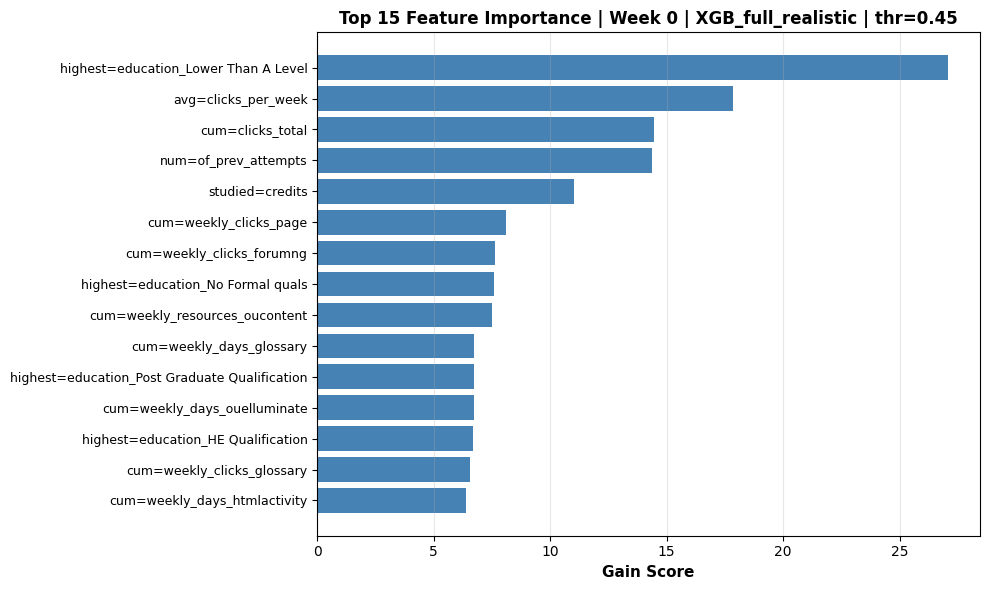

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_feature_importance_top15__week4__thr0.45.png


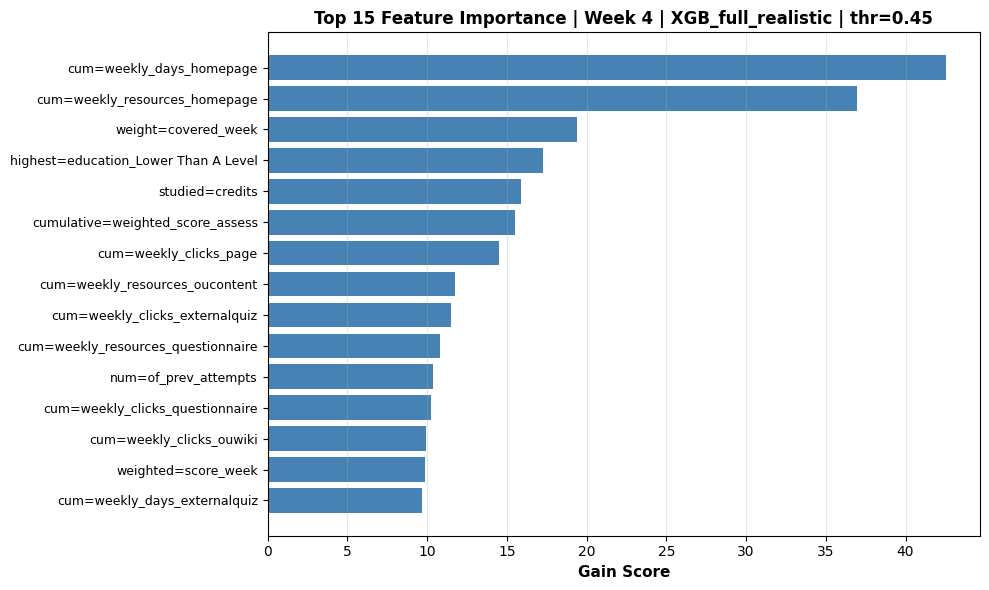

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_feature_importance_top15__week8__thr0.45.png


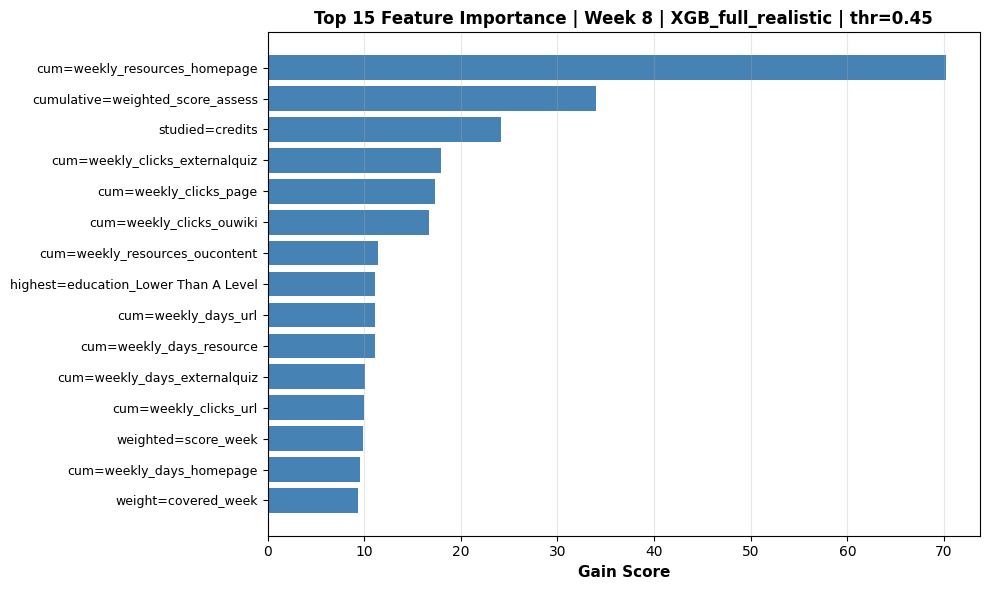

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_feature_importance_top15__week12__thr0.45.png


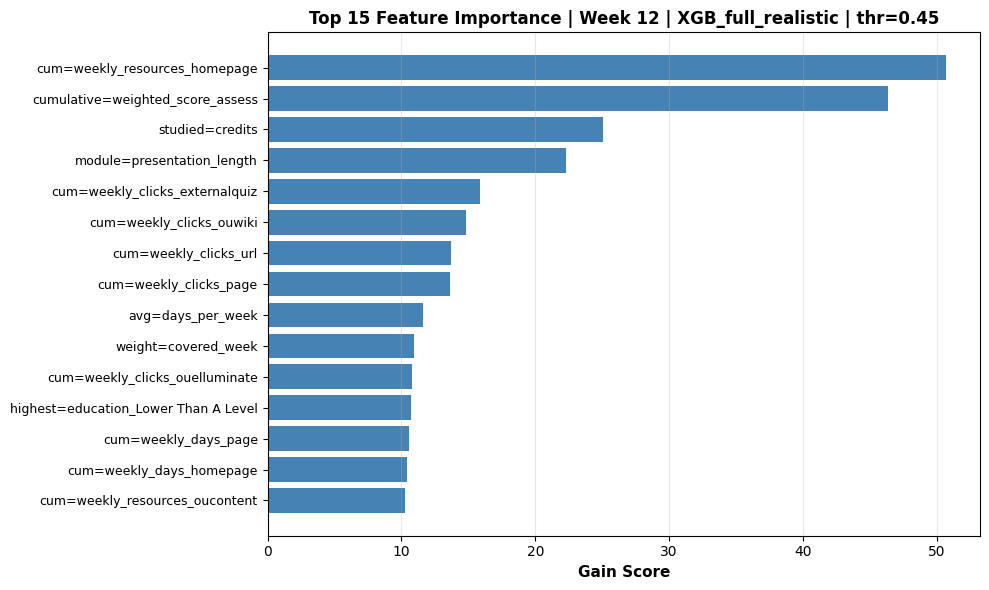

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_feature_importance_top15__week16__thr0.45.png


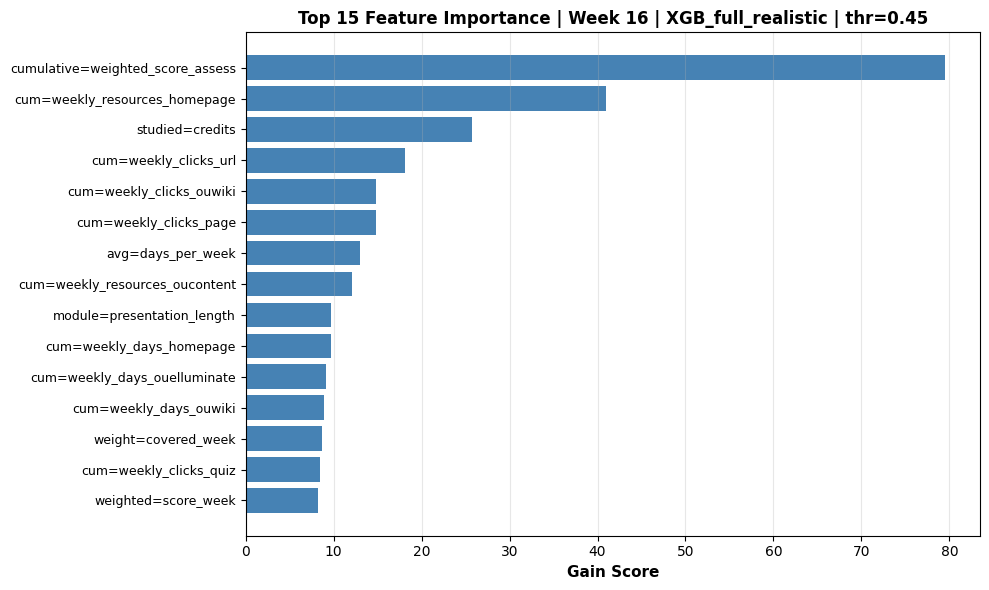

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_feature_importance_top15__week20__thr0.45.png


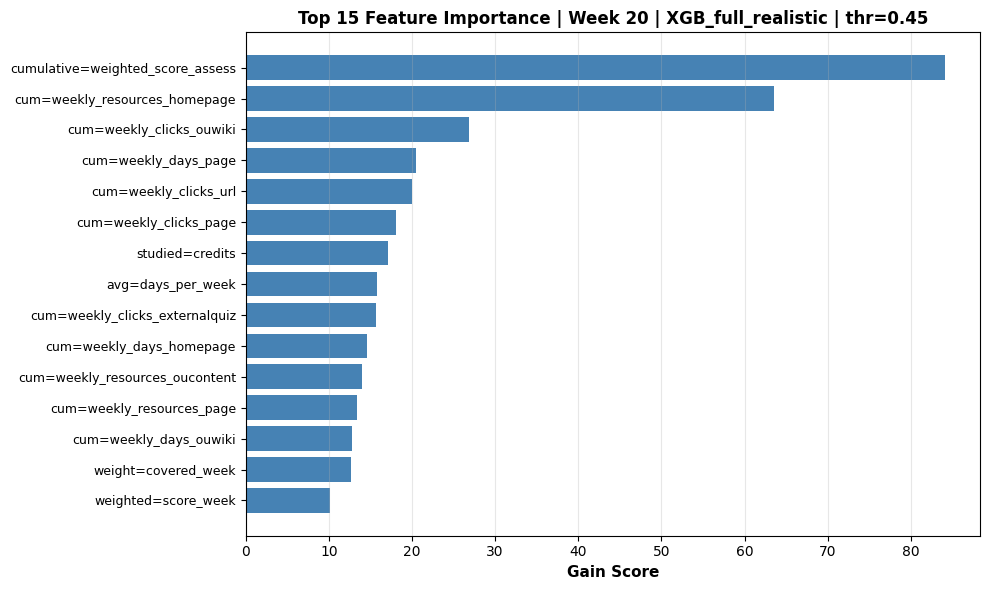

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_feature_importance_top15__week24__thr0.45.png


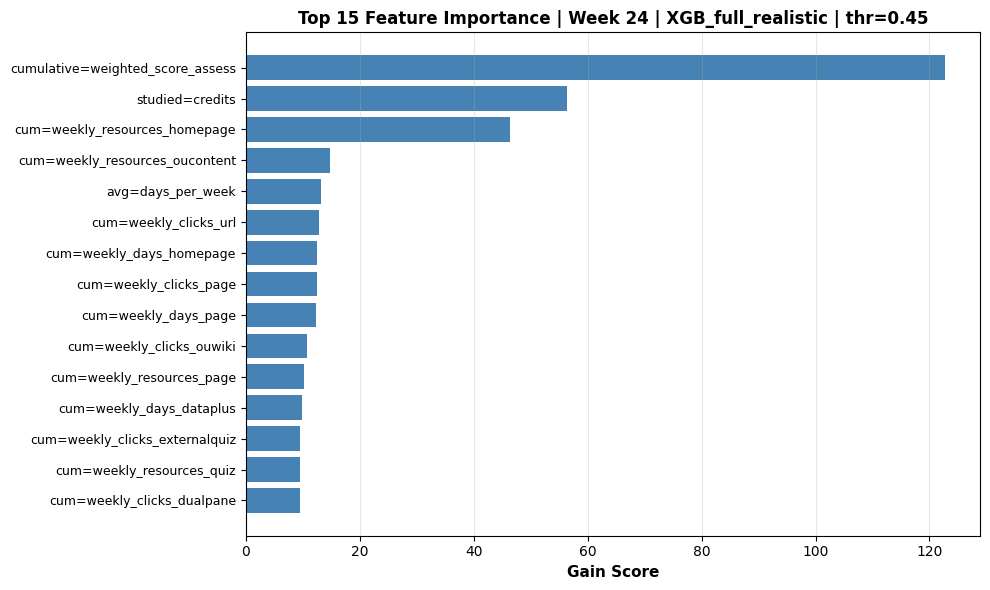

Saved figure: /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures/xgb_feature_importance_top15__week28__thr0.45.png


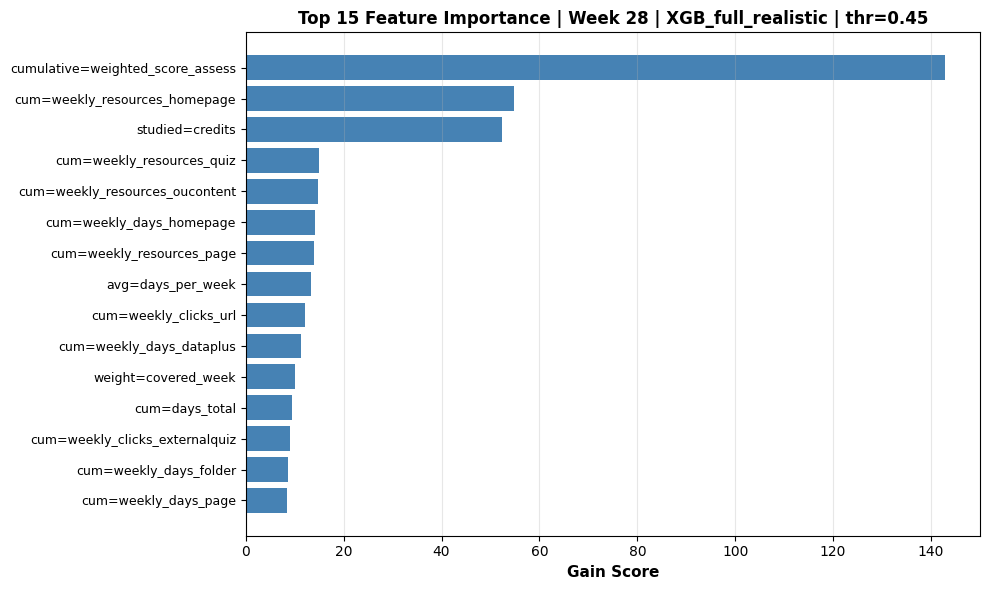


✓ Feature importance visualizations saved to /Users/wasimhoque/Documents/Data Mining/WM9QG-Group-Project/reports/xgb_classification/figures
  - Heatmap: xgb_feature_importance_heatmap__XGB_full_realistic__thr0.45.png
  - Bar plots: xgb_feature_importance_top15__week[0,4,8,...]__thr0.45.png


,feature,importance,week_t
0,highest=education_Lower Than A Level,27.100327,0
1,avg=clicks_per_week,17.851633,0
2,cum=clicks_total,14.462269,0
3,num=of_prev_attempts,14.362863,0
4,studied=credits,11.015117,0


In [10]:
top_n = 15
step = 1

all_top = []
for t in weeks[::step]:
    r = run_xgb_week(df, t, drop_cols=drop_cols, params=xgb_params, threshold=threshold)
    clf = r["clf"]
    booster = clf.get_booster()
    score_gain = booster.get_score(importance_type="gain")  # keys like f0, f1...

    imp_vals = np.zeros(len(r["feature_names"]), dtype=float)
    for k, v in score_gain.items():
        if k.startswith("f"):
            j = int(k[1:])
            if 0 <= j < len(imp_vals):
                imp_vals[j] = float(v)

    imp_df = (
        pd.DataFrame({"feature": r["feature_names"], "importance": imp_vals})
          .sort_values("importance", ascending=False)
          .head(top_n)
          .reset_index(drop=True)
    )
    imp_df["week_t"] = int(t)
    all_top.append(imp_df)

xgb_fi_long = pd.concat(all_top, ignore_index=True)
fi_long_path = FEAT_DIR / f"xgb_top_features_over_time__{slug(exp_name)}__every{step}w__gain.csv"
xgb_fi_long.to_csv(fi_long_path, index=False)
print("Saved:", fi_long_path)

# ============================================================================
# Visualization 1: Heatmap of top N features over time
# ============================================================================
pivot_importance = xgb_fi_long.pivot_table(
    index="feature", 
    columns="week_t", 
    values="importance", 
    fill_value=0
)

# Get the top features (aggregate importance across all weeks)
top_features = xgb_fi_long.groupby("feature")["importance"].sum().nlargest(top_n).index
pivot_importance = pivot_importance.loc[top_features]

fig, ax = plt.subplots(figsize=(14, 8))
im = ax.imshow(pivot_importance.values, cmap="YlOrRd", aspect="auto")

ax.set_xticks(range(len(pivot_importance.columns)))
ax.set_xticklabels(pivot_importance.columns, rotation=45, ha="right")
ax.set_yticks(range(len(pivot_importance.index)))
ax.set_yticklabels(pivot_importance.index, fontsize=9)

ax.set_xlabel("Week", fontsize=11, fontweight="bold")
ax.set_ylabel("Feature", fontsize=11, fontweight="bold")
ax.set_title(f"Top {top_n} Feature Importance Heatmap Over Time\n{exp_name} | threshold={threshold:.2f}", 
             fontsize=12, fontweight="bold")

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Gain Score", fontsize=10)

plt.tight_layout()
heatmap_path = FIG_DIR / f"xgb_feature_importance_heatmap__{slug(exp_name)}__thr{threshold:.2f}.png"
savefig(heatmap_path)
plt.show()

# ============================================================================
# Visualization 2: Bar plots for selected weeks
# ============================================================================
weeks_to_plot = [w for w in weeks if w % 4 == 0]  # Every 4th week for clarity

for week_num in weeks_to_plot:
    week_data = xgb_fi_long[xgb_fi_long["week_t"] == week_num].sort_values("importance", ascending=True)
    
    if len(week_data) == 0:
        continue
    
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(range(len(week_data)), week_data["importance"].values, color="steelblue")
    ax.set_yticks(range(len(week_data)))
    ax.set_yticklabels(week_data["feature"].values, fontsize=9)
    ax.set_xlabel("Gain Score", fontsize=11, fontweight="bold")
    ax.set_title(f"Top {top_n} Feature Importance | Week {week_num} | {exp_name} | thr={threshold:.2f}",
                 fontsize=12, fontweight="bold")
    ax.grid(axis="x", alpha=0.3)
    
    plt.tight_layout()
    bar_path = FIG_DIR / f"xgb_feature_importance_top{top_n}__week{week_num}__thr{threshold:.2f}.png"
    savefig(bar_path)
    plt.show()

print(f"\n✓ Feature importance visualizations saved to {FIG_DIR}")
print(f"  - Heatmap: xgb_feature_importance_heatmap__{slug(exp_name)}__thr{threshold:.2f}.png")
print(f"  - Bar plots: xgb_feature_importance_top{top_n}__week[0,4,8,...]__thr{threshold:.2f}.png")

xgb_fi_long.head()

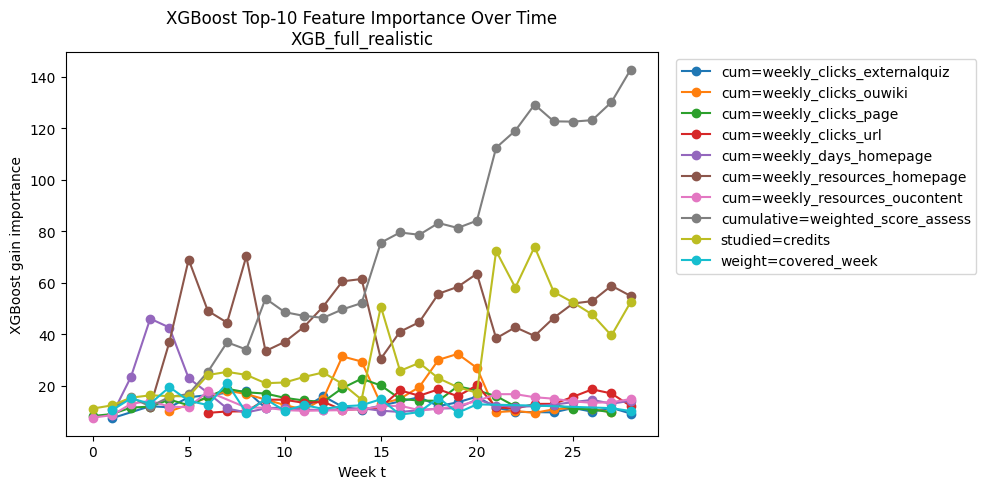

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# load long-form importance
fi = pd.read_csv(FEAT_DIR / f"xgb_top_features_over_time__{slug(exp_name)}__every1w__gain.csv")

top_k = 10

# select top-K features globally (sum of gain over time)
top_feats = (
    fi.groupby("feature")["importance"]
      .sum()
      .sort_values(ascending=False)
      .head(top_k)
      .index
)

plot_df = fi[fi["feature"].isin(top_feats)].copy()

plt.figure(figsize=(10, 5))
for feat, g in plot_df.groupby("feature"):
    g = g.sort_values("week_t")
    plt.plot(g["week_t"], g["importance"], marker="o", label=feat)

plt.xlabel("Week t")
plt.ylabel("XGBoost gain importance")
plt.title(f"XGBoost Top-{top_k} Feature Importance Over Time\n{exp_name}")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()